# Assessment 3 – Regression Analysis
## Regression 2.1: Predicting Goal Difference

**Dataset:** FIFA World Cup 2026 Match Results

**Prepared by:** Diwash

### Introduction
This task uses FIFA World Cup 2026 match data to study the goal difference between two opposing teams. The dataset contains 104 matches from the group stage to the final.

The aim is to prepare a clean dataset with match results and eight explanatory variables that were known before each match. This dataset will later be used to build and evaluate a regression model.


### 1. Import Libraries and Load Dataset

In this step, we import the Pandas library and load the FIFA World Cup 2026 match results.

Pandas helps us read, clean and analyse data using Python.

The dataset contains the match dates, teams, scores, rounds and venues.


In [1]:

# Import the required library
import pandas as pd

# Read the FIFA World Cup 2026 match results CSV
file_path = "../../data/raw/FIFA_2026_Match_Results_Raw.csv"

df = pd.read_csv(file_path, encoding="utf-8-sig")

# Check the number of matches and available columns
print("Total matches:", len(df))
print("Dataset columns:", df.columns.tolist())

# Display the first five matches
display(df.head())


Total matches: 104
Dataset columns: ['Round', 'Wk', 'Day', 'Date', 'Time', 'Home', 'Score', 'Away', 'Attendance', 'Venue', 'Referee', 'Match Report', 'Notes']


,Round,Wk,Day,Date,Time,Home,Score,Away,Attendance,Venue,Referee,Match Report,Notes
0,Group stage,1.0,Thu,2026-06-11,13:00 (05:00),Mexico mx,2–0,za South Africa,80824,Estadio Banorte (Neutral Site),Wilton Sampaio,Match Report,NaN
1,Group stage,1.0,Thu,2026-06-11,20:00 (12:00),Korea Republic kr,2–1,cz Czechia,44985,Estadio Akron (Neutral Site),Amin Omar,Match Report,NaN
2,Group stage,1.0,Fri,2026-06-12,15:00 (05:00),Canada ca,1–1,ba Bosnia–Herz,43002,BMO Field (Neutral Site),Facundo Tello,Match Report,NaN
3,Group stage,1.0,Fri,2026-06-12,18:00 (11:00),USA us,4–1,py Paraguay,70492,SoFi Stadium (Neutral Site),Danny Makkelie,Match Report,NaN
4,Group stage,1.0,Sat,2026-06-13,12:00 (05:00),Qatar qa,1–1,ch Switzerland,67966,Levi's Stadium (Neutral Site),Said Martínez,Match Report,NaN



### 2. Data Understanding

This section examines the structure and quality of the FIFA World Cup 2026 dataset.

The dataset contains 104 matches, covering the group stage and knockout rounds.

We check the number of rows and columns, data types, missing values, and duplicate records before cleaning the data.


In [2]:

# Check the size of the dataset
print("Dataset shape:", df.shape)

# Display column names and data types
print("\nDataset information:")
df.info()

# Check missing values in each column
print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

# Check duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

# Count matches in each tournament round
print("\nMatches by round:")
display(df["Round"].value_counts().to_frame("Number of Matches"))


Dataset shape: (104, 13)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 104 entries, 0 to 103
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Round         104 non-null    str    
 1   Wk            72 non-null     float64
 2   Day           104 non-null    str    
 3   Date          104 non-null    str    
 4   Time          104 non-null    str    
 5   Home          104 non-null    str    
 6   Score         104 non-null    str    
 7   Away          104 non-null    str    
 8   Attendance    104 non-null    int64  
 9   Venue         104 non-null    str    
 10  Referee       104 non-null    str    
 11  Match Report  104 non-null    str    
 12  Notes         9 non-null      str    
dtypes: float64(1), int64(1), str(11)
memory usage: 23.3 KB

Missing values:


,Missing Values
Round,0
Wk,32
Day,0
Date,0
Time,0
Home,0
Score,0
Away,0
Attendance,0
Venue,0



Duplicate rows: 0

Matches by round:


,Number of Matches
Round,
Group stage,72
Round of 32,16
Round of 16,8
Quarter-finals,4
Semi-finals,2
Third-place match,1
Final,1



### 3. Data Cleaning and Preparation

In this section, we clean the match results to make them suitable for regression analysis.

The original dataset contains team names with country codes and some scores with penalty shoot-out information.

We remove unnecessary country codes, extract the actual match goals, and calculate the goal difference.

Penalty shoot-out scores are not included in the goal difference because they are separate from match goals.


In [3]:

import re

# Create a copy to protect the original dataset
matches = df.copy()

# Remove country codes from team names
def clean_team_name(name):
    name = str(name).strip()

    # Remove country codes at the beginning
    name = re.sub(r"^[a-z]{2,3}\s+", "", name)

    # Remove country codes at the end
    name = re.sub(r"\s+[a-z]{2,3}$", "", name)

    return name.strip()

matches["Home"] = matches["Home"].apply(clean_team_name)
matches["Away"] = matches["Away"].apply(clean_team_name)

# Extract match goals, ignoring penalty shoot-out scores
def extract_goals(score):
    score = str(score)

    # Find the actual match score, e.g. 2–1 or 1–1
    result = re.search(r"(\d+)\s*[–-]\s*(\d+)", score)

    if result:
        return pd.Series([int(result.group(1)),
                          int(result.group(2))])

    return pd.Series([None, None])

matches[["Home_Goals", "Away_Goals"]] = (
    matches["Score"].apply(extract_goals)
)

# Calculate the goal difference
matches["Goal_Difference"] = (
    matches["Home_Goals"] - matches["Away_Goals"]
)

# Convert dates into datetime format
matches["Date"] = pd.to_datetime(matches["Date"])

# Display cleaned match data
display(matches[
    ["Date", "Round", "Home", "Away",
     "Home_Goals", "Away_Goals", "Goal_Difference"]
].head(10))

print("Total matches:", len(matches))
print("Missing goal values:",
      matches[["Home_Goals", "Away_Goals"]].isnull().sum().sum())


,Date,Round,Home,Away,Home_Goals,Away_Goals,Goal_Difference
0,2026-06-11,Group stage,Mexico,South Africa,2,0,2
1,2026-06-11,Group stage,Korea Republic,Czechia,2,1,1
2,2026-06-12,Group stage,Canada,Bosnia–Herz,1,1,0
3,2026-06-12,Group stage,USA,Paraguay,4,1,3
4,2026-06-13,Group stage,Qatar,Switzerland,1,1,0
5,2026-06-13,Group stage,Brazil,Morocco,1,1,0
6,2026-06-13,Group stage,Australia,Türkiye,2,0,2
7,2026-06-13,Group stage,Haiti,Scotland,0,1,-1
8,2026-06-14,Group stage,Germany,Curaçao,7,1,6
9,2026-06-14,Group stage,Netherlands,Japan,2,2,0


Total matches: 104
Missing goal values: 0



### 4. Population, Sampling and Data Filtering

**Population:** The population consists of all 104 matches played during the FIFA World Cup 2026.

**Sampling method:** We use complete enumeration (a census), rather than selecting a smaller sample. This allows us to include every match from the tournament.

**Data filtering:** We divide the matches into two groups:
- Group stage: 72 matches
- Knockout stage: 32 matches

The purpose is to compare the number of goals and goal differences between the two stages.

No matches are removed from the final regression dataset.


In [4]:

# Section 4: Population, Sampling and Filtering

# Calculate total goals in each match
matches["Total_Goals"] = (
    matches["Home_Goals"] + matches["Away_Goals"]
)

# Divide matches into group stage and knockout stage
group_matches = matches[
    matches["Round"] == "Group stage"
].copy()

knockout_matches = matches[
    matches["Round"] != "Group stage"
].copy()

# Display the number of matches
print("Total population:", len(matches))
print("Group-stage matches:", len(group_matches))
print("Knockout-stage matches:", len(knockout_matches))

# Compare goals and goal differences by stage
stage_summary = pd.DataFrame({
    "Stage": ["Group stage", "Knockout stage"],
    "Matches": [len(group_matches), len(knockout_matches)],
    "Average Goals": [
        group_matches["Total_Goals"].mean(),
        knockout_matches["Total_Goals"].mean()
    ],
    "Average Absolute Goal Difference": [
        group_matches["Goal_Difference"].abs().mean(),
        knockout_matches["Goal_Difference"].abs().mean()
    ]
})

display(stage_summary.round(2))


Total population: 104
Group-stage matches: 72
Knockout-stage matches: 32


,Stage,Matches,Average Goals,Average Absolute Goal Difference
0,Group stage,72,2.99,1.65
1,Knockout stage,32,2.91,1.34


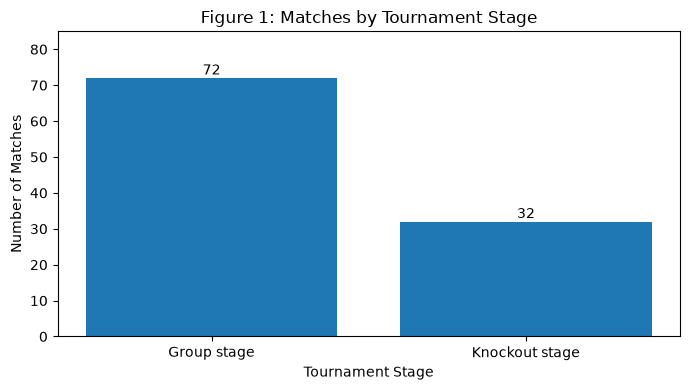

In [5]:

import matplotlib.pyplot as plt

# Figure 1: Number of matches by tournament stage
stages = ["Group stage", "Knockout stage"]
counts = [len(group_matches), len(knockout_matches)]

plt.figure(figsize=(7, 4))
bars = plt.bar(stages, counts)

# Display values above the bars
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        int(bar.get_height()),
        ha="center"
    )

plt.title("Figure 1: Matches by Tournament Stage")
plt.xlabel("Tournament Stage")
plt.ylabel("Number of Matches")
plt.ylim(0, 85)
plt.tight_layout()
plt.show()



**Interpretation of Figure 1**

The dataset contains 104 matches, including 72 group-stage matches (69.2%) and 32 knockout-stage matches (30.8%). All matches are included in the analysis to ensure complete data coverage. The difference in the number of matches between stages is considered when comparing their performance statistics.



### 5. Descriptive Statistics and Exploratory Data Analysis

This section summarises the scoring patterns in the FIFA World Cup 2026.

We calculate the mean, median, standard deviation, minimum and maximum for goals scored and goal difference.

We also use graphs to understand the distribution of goals and identify unusual results.

These statistics describe the match outcomes. They are not used as pre-match explanatory variables in the regression model.


In [6]:

# Section 5: Descriptive Statistics

# Select the numerical variables for analysis
numeric_columns = [
    "Home_Goals",
    "Away_Goals",
    "Total_Goals",
    "Goal_Difference"
]

# Calculate descriptive statistics
descriptive_stats = matches[numeric_columns].describe()

# Display the statistics
print("Descriptive Statistics of FIFA World Cup 2026 Matches")
display(descriptive_stats.round(2))

# Calculate average goals per match
print("Average goals per match:",
      round(matches["Total_Goals"].mean(), 2))

# Calculate the number of drawn matches
draws = (matches["Goal_Difference"] == 0).sum()
print("Matches ending in a draw:", draws)


Descriptive Statistics of FIFA World Cup 2026 Matches


,Home_Goals,Away_Goals,Total_Goals,Goal_Difference
count,104.00,104.00,104.00,104.00
mean,1.72,1.24,2.96,0.48
std,1.50,1.23,1.86,2.02
min,0.00,0.00,0.00,-4.00
25%,1.00,0.00,2.00,-1.00
50%,1.00,1.00,3.00,0.00
75%,3.00,2.00,4.00,2.00
max,7.00,6.00,10.00,6.00


Average goals per match: 2.96
Matches ending in a draw: 24


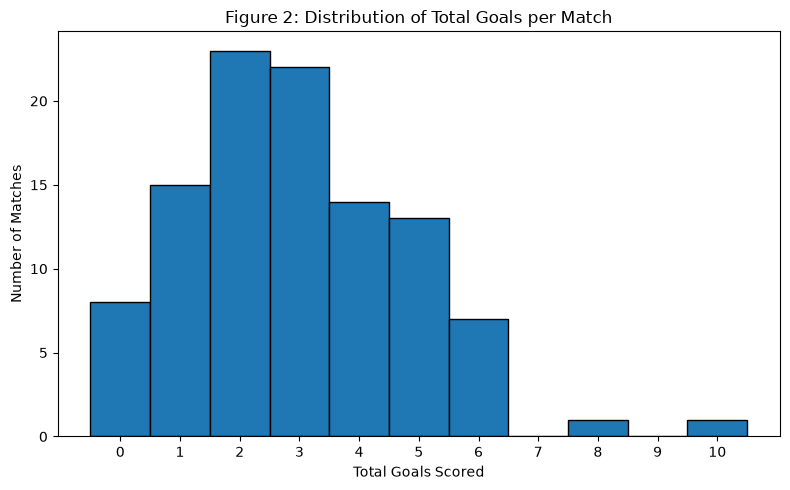

In [7]:

import matplotlib.pyplot as plt

# Figure 2: Distribution of total goals per match
plt.figure(figsize=(8, 5))

plt.hist(
    matches["Total_Goals"],
    bins=range(
        0,
        int(matches["Total_Goals"].max()) + 2
    ),
    edgecolor="black",
    align="left"
)

plt.title("Figure 2: Distribution of Total Goals per Match")
plt.xlabel("Total Goals Scored")
plt.ylabel("Number of Matches")
plt.xticks(range(int(matches["Total_Goals"].max()) + 1))
plt.tight_layout()
plt.show()


**Interpretation of Figure 2**

Figure 2 shows that most FIFA World Cup 2026 matches had between 1 and 5 goals, with 2 and 3 goals occurring most frequently. Very high-scoring matches were uncommon, with only a few matches reaching 8 or more goals. This suggests that the distribution is concentrated around lower goal totals, with a small number of unusually high-scoring matches.


### 5.1 Goal Difference Analysis

Goal difference is calculated by subtracting the away team's goals from the home team's goals.

A positive value means the home team scored more goals, a negative value means the away team scored more goals, and zero means the match was drawn.

We use a box plot to examine the distribution of goal differences and identify unusual match results.


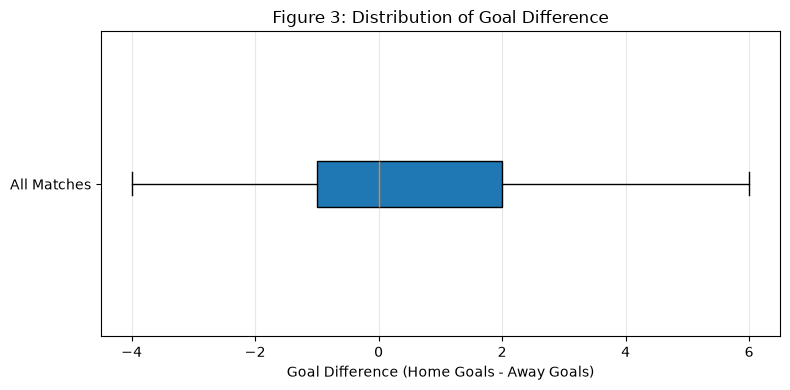

Mean goal difference: 0.48
Median goal difference: 0.0
Minimum goal difference: -4
Maximum goal difference: 6
Standard deviation: 2.02


In [10]:

# Figure 3: Distribution of Goal Difference

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

plt.boxplot(
    matches["Goal_Difference"],
    orientation="horizontal",
    patch_artist=True
)

plt.title("Figure 3: Distribution of Goal Difference")
plt.xlabel("Goal Difference (Home Goals - Away Goals)")
plt.yticks([1], ["All Matches"])
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

# Summary of goal differences
print("Mean goal difference:",
      round(matches["Goal_Difference"].mean(), 2))

print("Median goal difference:",
      matches["Goal_Difference"].median())

print("Minimum goal difference:",
      matches["Goal_Difference"].min())

print("Maximum goal difference:",
      matches["Goal_Difference"].max())

print("Standard deviation:",
      round(matches["Goal_Difference"].std(), 2))



**Interpretation of Figure 3**

Figure 3 shows that goal differences ranged from -4 to +6, with a median of 0 and an average of 0.48 goals.

The standard deviation of 2.02 shows variation in the winning margins. The middle 50% of matches had goal differences of approximately -1 to +2.

The average is slightly positive, meaning the teams listed as home scored slightly more goals overall. However, many matches were played at neutral venues.

Goal difference will be used as the dependent variable in Regression 2.1.



### 5.2 Goals by Tournament Round

This section compares the average number of goals scored in each round of the FIFA World Cup 2026.

We use the average rather than total goals because different rounds contain different numbers of matches.

The analysis helps identify whether scoring patterns changed as the tournament progressed.


,Number_of_Matches,Average_Goals
Round,,
Group stage,72,2.99
Round of 32,16,2.62
Round of 16,8,2.88
Quarter-finals,4,3.00
Semi-finals,2,2.50
Third-place match,1,10.00
Final,1,1.00


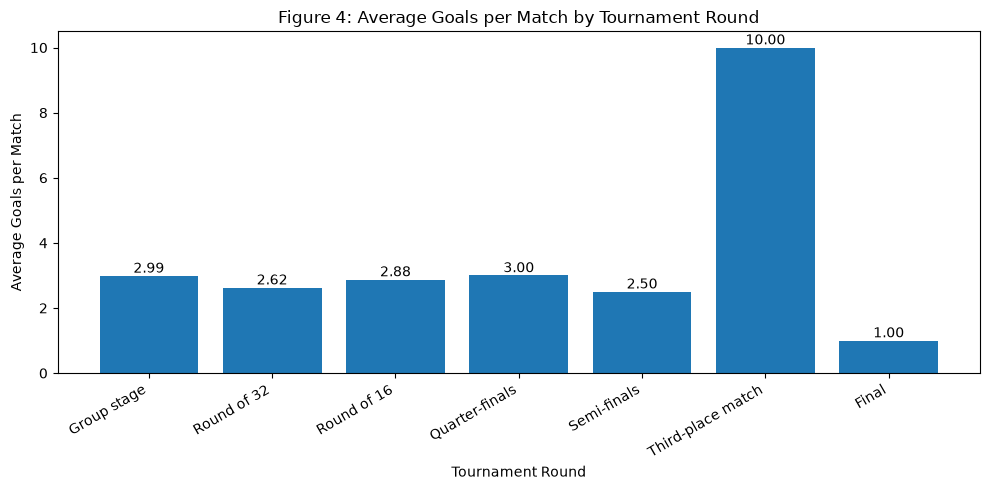

In [11]:

# Figure 4: Average goals per match by tournament round

import matplotlib.pyplot as plt

# Arrange tournament rounds in the correct order
round_order = [
    "Group stage",
    "Round of 32",
    "Round of 16",
    "Quarter-finals",
    "Semi-finals",
    "Third-place match",
    "Final"
]

# Calculate average goals for each round
round_summary = (
    matches.groupby("Round")["Total_Goals"]
    .agg(["count", "mean"])
    .reindex(round_order)
)

round_summary.columns = ["Number_of_Matches", "Average_Goals"]

# Display summary table
display(round_summary.round(2))

# Create bar chart
plt.figure(figsize=(10, 5))

bars = plt.bar(
    round_summary.index,
    round_summary["Average_Goals"]
)

# Add average goal values above each bar
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.1,
        f"{bar.get_height():.2f}",
        ha="center"
    )

plt.title("Figure 4: Average Goals per Match by Tournament Round")
plt.xlabel("Tournament Round")
plt.ylabel("Average Goals per Match")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()



**Interpretation of Figure 4**

Figure 4 shows that most tournament rounds averaged between 2.5 and 3 goals per match. The group stage averaged 2.99 goals, while the semi-finals averaged 2.50 goals.

The third-place match had the highest average of 10 goals, while the final had only 1 goal. However, both rounds contained only one match, so these results do not represent a general scoring trend.



### 6. Pre-Match Explanatory Variables

Regression 2.1 aims to predict the goal difference between two opposing teams using exactly eight explanatory variables.

All predictors must be available before the match begins. Therefore, we calculate historical performance using only earlier matches and avoid using final tournament statistics.

Before creating the predictors, we check the team names and match dates to ensure the records are suitable for chronological calculations.


In [13]:

# Check team names and match dates before feature engineering

# List all participating teams
teams = sorted(
    set(matches["Home"]).union(set(matches["Away"]))
)

print("Total unique teams:", len(teams))
print("\nTeams:")
print(teams)

# Check date range
print("\nFirst match:", matches["Date"].min())
print("Last match:", matches["Date"].max())

# Sort matches chronologically
matches = matches.sort_values(
    by=["Date", "Time"],
    kind="stable"
).reset_index(drop=True)

# Display first five matches
display(matches[
    ["Date", "Home", "Away",
     "Home_Goals", "Away_Goals"]
].head())


Total unique teams: 48

Teams:
['Algeria', 'Argentina', 'Australia', 'Austria', 'Belgium', 'Bosnia–Herz', 'Brazil', 'Cabo Verde', 'Canada', 'Colombia', 'Congo DR', 'Croatia', 'Curaçao', 'Czechia', "Côte d'Ivoire", 'Ecuador', 'Egypt', 'England', 'France', 'Germany', 'Ghana', 'Haiti', 'IR Iran', 'Iraq', 'Japan', 'Jordan', 'Korea Republic', 'Mexico', 'Morocco', 'Netherlands', 'New Zealand', 'Norway', 'Panama', 'Paraguay', 'Portugal', 'Qatar', 'Saudi Arabia', 'Scotland', 'Senegal', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Tunisia', 'Türkiye', 'USA', 'Uruguay', 'Uzbekistan']

First match: 2026-06-11 00:00:00
Last match: 2026-07-19 00:00:00


,Date,Home,Away,Home_Goals,Away_Goals
0,2026-06-11,Mexico,South Africa,2,0
1,2026-06-11,Korea Republic,Czechia,2,1
2,2026-06-12,Canada,Bosnia–Herz,1,1
3,2026-06-12,USA,Paraguay,4,1
4,2026-06-13,Qatar,Switzerland,1,1



### 6.1 Historical Team Performance

This section prepares historical performance statistics for each team.

Only matches played before the current match are used. This prevents data leakage and makes the explanatory variables suitable for prediction.

For teams playing their first match, previous tournament statistics are unavailable. These will be handled using a documented starting value.

The historical statistics include goals scored, goals conceded, wins, points, clean sheets and rest days.


In [14]:

# Section 6.1: Historical Team Performance

from collections import defaultdict

# Store completed matches for each team
team_history = defaultdict(list)

# Store historical information before each match
historical_records = []

# Process matches in chronological order
for _, match in matches.iterrows():

    home = match["Home"]
    away = match["Away"]
    match_date = match["Date"]

    # Get previous matches only
    home_history = team_history[home]
    away_history = team_history[away]

    # Calculate historical statistics
    def previous_stats(history, current_date):

        if len(history) == 0:
            return {
                "Matches": 0,
                "Avg_Goals_For": 0,
                "Avg_Goals_Against": 0,
                "Avg_Goal_Difference": 0,
                "Win_Rate": 0,
                "Points_Per_Game": 0,
                "Clean_Sheet_Rate": 0,
                "Rest_Days": 0
            }

        games = len(history)

        goals_for = sum(g["GF"] for g in history)
        goals_against = sum(g["GA"] for g in history)

        wins = sum(g["GF"] > g["GA"] for g in history)
        draws = sum(g["GF"] == g["GA"] for g in history)
        clean_sheets = sum(g["GA"] == 0 for g in history)

        return {
            "Matches": games,
            "Avg_Goals_For": goals_for / games,
            "Avg_Goals_Against": goals_against / games,
            "Avg_Goal_Difference": (
                goals_for - goals_against
            ) / games,
            "Win_Rate": wins / games,
            "Points_Per_Game": (3 * wins + draws) / games,
            "Clean_Sheet_Rate": clean_sheets / games,
            "Rest_Days": (
                current_date - history[-1]["Date"]
            ).days
        }

    home_stats = previous_stats(home_history, match_date)
    away_stats = previous_stats(away_history, match_date)

    # Store statistics before the current match
    historical_records.append({
        "Home": home,
        "Away": away,
        "Date": match_date,
        "Home_Stats": home_stats,
        "Away_Stats": away_stats
    })

    # Update histories only after recording pre-match statistics
    team_history[home].append({
        "Date": match_date,
        "GF": match["Home_Goals"],
        "GA": match["Away_Goals"]
    })

    team_history[away].append({
        "Date": match_date,
        "GF": match["Away_Goals"],
        "GA": match["Home_Goals"]
    })

print("Historical records created:", len(historical_records))

# Check the first record
print("\nFirst match historical information:")
print(historical_records[0])



Historical records created: 104

First match historical information:
{'Home': 'Mexico', 'Away': 'South Africa', 'Date': Timestamp('2026-06-11 00:00:00'), 'Home_Stats': {'Matches': 0, 'Avg_Goals_For': 0, 'Avg_Goals_Against': 0, 'Avg_Goal_Difference': 0, 'Win_Rate': 0, 'Points_Per_Game': 0, 'Clean_Sheet_Rate': 0, 'Rest_Days': 0}, 'Away_Stats': {'Matches': 0, 'Avg_Goals_For': 0, 'Avg_Goals_Against': 0, 'Avg_Goal_Difference': 0, 'Win_Rate': 0, 'Points_Per_Game': 0, 'Clean_Sheet_Rate': 0, 'Rest_Days': 0}}



### 6.2 Feature Engineering: Eight Pre-Match Variables

This section creates eight explanatory variables to predict the goal difference between two teams.

Seven variables compare the teams' previous tournament performance, including scoring, defending, winning and rest days. The eighth variable represents tournament host advantage.

Only information available before each match is used.

For the first match of each team, historical performance values are set to zero because no earlier tournament matches are available. These are neutral placeholders, not actual performance measurements.


In [17]:

# Section 6.2: Create eight pre-match explanatory variables

feature_records = []

# Tournament host nations
host_nations = {"Canada", "Mexico", "USA"}

for record in historical_records:

    home_stats = record["Home_Stats"]
    away_stats = record["Away_Stats"]

    home = record["Home"]
    away = record["Away"]

    # Difference between the two teams' pre-match statistics
    features = {
        "Prior_Goal_Diff_Diff":
            home_stats["Avg_Goal_Difference"] -
            away_stats["Avg_Goal_Difference"],

        "Prior_Goals_For_Diff":
            home_stats["Avg_Goals_For"] -
            away_stats["Avg_Goals_For"],

        "Prior_Goals_Against_Diff":
            home_stats["Avg_Goals_Against"] -
            away_stats["Avg_Goals_Against"],

        "Prior_Points_Per_Game_Diff":
            home_stats["Points_Per_Game"] -
            away_stats["Points_Per_Game"],

        "Prior_Win_Rate_Diff":
            home_stats["Win_Rate"] -
            away_stats["Win_Rate"],

        "Prior_Clean_Sheet_Rate_Diff":
            home_stats["Clean_Sheet_Rate"] -
            away_stats["Clean_Sheet_Rate"],

        "Rest_Days_Diff":
            home_stats["Rest_Days"] -
            away_stats["Rest_Days"],

        "Host_Nation_Advantage":
            int(home in host_nations) -
            int(away in host_nations)
    }

    feature_records.append(features)

# Convert predictor records into a DataFrame
features_df = pd.DataFrame(feature_records)

# Combine the original match data with predictors
regression_2_1 = pd.concat(
    [matches.reset_index(drop=True), features_df],
    axis=1
)

# Display the number of explanatory variables
print("Number of explanatory variables:", features_df.shape[1])
print("Total matches:", len(regression_2_1))

# Display the first five records
display(features_df.head())


Number of explanatory variables: 8
Total matches: 104


,Prior_Goal_Diff_Diff,Prior_Goals_For_Diff,Prior_Goals_Against_Diff,Prior_Points_Per_Game_Diff,Prior_Win_Rate_Diff,Prior_Clean_Sheet_Rate_Diff,Rest_Days_Diff,Host_Nation_Advantage
0,0.0,0.0,0.0,0.0,0.0,0.0,0,1
1,0.0,0.0,0.0,0.0,0.0,0.0,0,0
2,0.0,0.0,0.0,0.0,0.0,0.0,0,1
3,0.0,0.0,0.0,0.0,0.0,0.0,0,1
4,0.0,0.0,0.0,0.0,0.0,0.0,0,0



### 6.3 Improving and Validating the Predictors

Before preparing the final dataset, we review the explanatory variables.

We replace a redundant goal-difference predictor with the difference in previous matches played. This helps reduce exact multicollinearity.

For matches where either team has no previous tournament match, the rest-day difference is set to zero as a neutral placeholder.

All eight predictors use information available before each match.


In [18]:

# Section 6.3: Improve the explanatory variables

# Replace the redundant goal-difference predictor
features_df = features_df.drop(
    columns=["Prior_Goal_Diff_Diff"]
)

# Difference in number of previous matches played
features_df["Prior_Matches_Played_Diff"] = [
    record["Home_Stats"]["Matches"] -
    record["Away_Stats"]["Matches"]
    for record in historical_records
]

# Handle rest days when a team has no previous match
for i, record in enumerate(historical_records):

    home_games = record["Home_Stats"]["Matches"]
    away_games = record["Away_Stats"]["Matches"]

    if home_games == 0 or away_games == 0:
        features_df.loc[i, "Rest_Days_Diff"] = 0

# Rebuild the regression dataset with updated predictors
regression_2_1 = pd.concat(
    [matches.reset_index(drop=True), features_df],
    axis=1
)

# Check dataset dimensions
print("Total matches:", len(regression_2_1))
print("Number of explanatory variables:", len(features_df.columns))

# Check missing predictor values
print("\nMissing predictor values:")
print(features_df.isnull().sum())

# Display the updated predictors
display(features_df.head())


Total matches: 104
Number of explanatory variables: 8

Missing predictor values:
Prior_Goals_For_Diff           0
Prior_Goals_Against_Diff       0
Prior_Points_Per_Game_Diff     0
Prior_Win_Rate_Diff            0
Prior_Clean_Sheet_Rate_Diff    0
Rest_Days_Diff                 0
Host_Nation_Advantage          0
Prior_Matches_Played_Diff      0
dtype: int64


,Prior_Goals_For_Diff,Prior_Goals_Against_Diff,Prior_Points_Per_Game_Diff,Prior_Win_Rate_Diff,Prior_Clean_Sheet_Rate_Diff,Rest_Days_Diff,Host_Nation_Advantage,Prior_Matches_Played_Diff
0,0.0,0.0,0.0,0.0,0.0,0,1,0
1,0.0,0.0,0.0,0.0,0.0,0,0,0
2,0.0,0.0,0.0,0.0,0.0,0,1,0
3,0.0,0.0,0.0,0.0,0.0,0,1,0
4,0.0,0.0,0.0,0.0,0.0,0,0,0



### 7. Final Dataset and Validation

The final dataset contains 104 matches and eight explanatory variables based on information available before each match.

Goal difference is the dependent variable. The dataset is checked for missing values and saved as a CSV file for regression modelling.

Historical variables for teams' first matches use neutral placeholder values because previous tournament performance is unavailable.


In [19]:

from pathlib import Path

# Select identification columns, target, and 8 predictors
final_columns = [
    "Date", "Round", "Home", "Away",
    "Home_Goals", "Away_Goals", "Goal_Difference"
] + features_df.columns.tolist()

final_df = regression_2_1[final_columns].copy()

# Validate the final dataset
assert len(final_df) == 104
assert len(features_df.columns) == 8
assert final_df["Goal_Difference"].notna().all()
assert final_df[features_df.columns].notna().all().all()

# Create the output folder
output_folder = Path("../data")
output_folder.mkdir(parents=True, exist_ok=True)

# Save the CSV
output_path = output_folder / "regression_2_1.csv"
final_df.to_csv(output_path, index=False)

print("Dataset saved successfully!")
print("Location:", output_path)
print("Total matches:", len(final_df))
print("Explanatory variables:", len(features_df.columns))

display(final_df.head())


Dataset saved successfully!
Location: ..\data\regression_2_1.csv
Total matches: 104
Explanatory variables: 8


,Date,Round,Home,Away,Home_Goals,Away_Goals,Goal_Difference,Prior_Goals_For_Diff,Prior_Goals_Against_Diff,Prior_Points_Per_Game_Diff,Prior_Win_Rate_Diff,Prior_Clean_Sheet_Rate_Diff,Rest_Days_Diff,Host_Nation_Advantage,Prior_Matches_Played_Diff
0,2026-06-11,Group stage,Mexico,South Africa,2,0,2,0.0,0.0,0.0,0.0,0.0,0,1,0
1,2026-06-11,Group stage,Korea Republic,Czechia,2,1,1,0.0,0.0,0.0,0.0,0.0,0,0,0
2,2026-06-12,Group stage,Canada,Bosnia–Herz,1,1,0,0.0,0.0,0.0,0.0,0.0,0,1,0
3,2026-06-12,Group stage,USA,Paraguay,4,1,3,0.0,0.0,0.0,0.0,0.0,0,1,0
4,2026-06-13,Group stage,Qatar,Switzerland,1,1,0,0.0,0.0,0.0,0.0,0.0,0,0,0


### Conclusion – Regression 2.1 Dataset Preparation

This task successfully prepared a dataset containing **104 FIFA World Cup 2026 matches** for predicting goal differences between opposing teams.

Eight explanatory variables were developed using historical match information available before each match. The dataset was checked for missing values and organized for regression analysis.

The final dataset was saved as `regression_2_1.csv` and is ready for model training and evaluation by Kshitiz.

Overall, this task provides the necessary data foundation for Regression 2.1.